# 02 — Phase 1a: MCQ Distractor Generation Experiments

**MCQ distractor generation pipeline** (200 random questions, 9 conditions, 3 runs = 5,400 evaluations):

1. **Data & Setup** — Load Eedi misconception bank and frozen 200-question test set
2. **Prompt Design** — 4 system × 3 instruction × misconception-conditioned variants
3. **Generation** — Run all 9 experimental conditions
4. **Evaluation** — Compute all 5 metrics (3 F1 + 2 F2) with parallel LLM judges
5. **Results** — Compare conditions against Feng et al. (2024) baselines

**Model:** `meta-llama/Llama-3.3-70B-Instruct` (generator + judge), `Snowflake/snowflake-arctic-embed-l-v2.0` (embedder)

**Results summary:** Best PM 21.9% (#03), Best Validity 83.0% (#05), Best Diversity 43.8% (#07). Clear PM–Diversity tradeoff discovered.

## 1. Environment & Imports

In [1]:
import sys, json, random, importlib
sys.path.insert(0, "..")

import numpy as np
import pandas as pd

# Force-reload if source changed since kernel start
import src.evaluation.mcq_metrics as _mcqm
importlib.reload(_mcqm)
from src.evaluation.mcq_metrics import (
    MCQEvaluator, ConditionResults,
)
from src.generation.misconception_bank import MisconceptionBank
from src.generation.mcq_generator import MCQGenerator

random.seed(42)
np.random.seed(42)

## 2. Load Data

Load the misconception bank (2,587 misconceptions, 1,869 questions) and the frozen test set (200 random questions, seed=42, ≥3 misconceptions each).

In [2]:
bank = MisconceptionBank().load()

with open("../data/eedi/test_set_200.json") as f:
    test_set = json.load(f)

print(f"Bank: {bank.question_count()} questions, {len(bank.misconceptions)} misconceptions")
print(f"Test set: {len(test_set)} questions")

from collections import Counter
for subj, cnt in Counter(q["SubjectName"] for q in test_set).most_common(8):
    print(f"  {subj}: {cnt}")

  Loaded 2587 misconceptions
  Loaded 1869 questions
  Indexed 2587 misconception embeddings
Bank: 1869 questions, 2587 misconceptions
Test set: 200 questions
  Averages (mean, median, mode) from a List of Data: 7
  Linear Sequences (nth term): 7
  Multiplying and Dividing with Decimals: 6
  Rounding to Decimal Places: 6
  Basic Angle Facts (straight line, opposite, around a point, etc): 5
  Other Sequences: 5
  Mental Addition and Subtraction: 5
  Percentages of an Amount: 5


### Sample questions

In [3]:
for q in test_set[:10]:
    correct = q["CorrectAnswer"]
    print(f"Q{q['QuestionId']} [{q['SubjectName']}]")
    print(f"  Q: {q['QuestionText'][:120]}...")
    for letter in ["A", "B", "C", "D"]:
        text = q.get(f"Answer{letter}Text", "")
        mc_id = q.get(f"Misconception{letter}Id", "")
        tick = " ✓" if correct == letter else ""
        mc = f" [MC:{int(mc_id)}]" if mc_id else ""
        if text:
            print(f"  {letter}: {text[:60]}{tick}{mc}")
    print()

Q590 [Construct Angle]
  Q: What is the name of the mathematical instrument used to construct circles?...
  A: Callipers [MC:295]
  B: Compass ✓
  C: Protractor [MC:295]
  D: Slide rule [MC:295]

Q117 [Sharing in a Ratio]
  Q: To make pink paint, you mix red paint with white paint in the ratio \( 3: 4 \).
What should replace the star? ![Red, Whi...
  A: \( 1201 \ \mathrm{ml} \) [MC:2356]
  B: \( 900 \ \mathrm{ml} \) [MC:105]
  C: \( 4800 \ \mathrm{ml} \) [MC:1646]
  D: \( 1600 \ \mathrm{ml} \) ✓

Q253 [Basic Angle Facts (straight line, opposite, around a point, etc)]
  Q: What is the size of angle \( k \) ? ![Three angles which meet to form a straight line. They are labelled 46 degrees, 115...
  A: \( 46^{\circ} \) [MC:2365]
  B: \( 65^{\circ} \) [MC:1707]
  C: \( 19^{\circ} \) ✓
  D: Not enough information [MC:725]

Q1199 [Time]
  Q: Which one of the following calculations would work out the number of hours in \( 5 \) weeks?...
  A: \( 5 \times 24 \) [MC:1179]
  B: \( 5 \times 7 \time

## 3. Prompt Design

Three orthogonal dimensions with critical output format fix.

### 3.1 System Prompt Variants (pedagogical framing depth)

| Variant | Depth | What it adds |
|---------|-------|-------------|
| `basic` | Minimal | "You are a helpful assistant" |
| `expert` | Domain | Math education expert, diagnosing misconceptions |
| `pedagogical` | Rich | 4 error categories (procedural/conceptual/factual/strategic), diagnostic reasoning |
| `lookalike` | Simulation | Thinks like a real student, makes authentic mistakes (Parikh 2025) |

### 3.2 Instruction Strategy Variants

| Variant | Strategy | Source |
|---------|----------|--------|
| `direct` | Generate immediately | Baseline |
| `cot` | 4-step chain-of-thought reasoning | Feng 2024 |
| `self_critique` | Generate → critique → revise | Madaan 2023 |

### 3.3 Few-Shot Variants

| Variant | What it does |
|---------|-------------|
| `fewshot_static` | 2 random bank questions with distractors as in-context examples |
| `fewshot_rag` | 2 embedding-similar questions retrieved via Arctic-embed-l-v2.0 |

Both use the `rationale` few-shot mode (examples show reasoning pattern). RAG requires an `EmbeddingIndex` — without it, falls back to random selection.

### 3.4 Output Format (normalized)

The test set has been normalized: `\( \frac{5}{13} \)` → `(5)/(13)`, `\( +9 \)` → `+9`, etc.
The output format instruction tells the generator to produce **bare answers** matching this normalized format — no LaTeX delimiters, no descriptions.

### Show a sample prompt

In [4]:
gen = MCQGenerator(bank=bank)

# Zero-shot prompt
messages_zs = gen._build_messages(
    question_text="What is 3 × 2 + 4 − 5?",
    correct_answer="5",
    strategy="zero_shot", n_distractors=3,
    system_variant="cot", instruction_variant="direct",
)
print("=== ZERO-SHOT USER PROMPT ===")
print(messages_zs[1]["content"])
print()

# Few-shot prompt (with 2 bank examples)
messages_fs = gen._build_messages(
    question_text="What is 3 × 2 + 4 − 5?",
    correct_answer="5",
    strategy="fewshot_static", n_distractors=3,
    system_variant="expert", instruction_variant="direct",
    fewshot_mode="rationale",
)
print("=== FEW-SHOT USER PROMPT ===")
print(messages_fs[1]["content"])

=== ZERO-SHOT USER PROMPT ===
Generate 3 plausible wrong distractors for the following math question.

Question: What is 3 × 2 + 4 − 5?
Correct answer: 5

For each distractor, provide:
- "text": The wrong answer a student would select
- "target_misconception": The name of the misconception this distractor targets (be specific — e.g., "Confuses addition with multiplication", "Forgets order of operations")
- "error_rationale": A brief 1-sentence explanation of why a student would pick this answer

The distractors must be plausible — they should look like answers a real student might produce.


CRITICAL — the "text" field must be the bare MATHEMATICAL ANSWER only, with NO LaTeX delimiters (`\(` `\)` `$`). NOT a description, NOT a sentence.

CORRECT format (bare answer):
  - Numbers: "6", "12.5", "-3"
  - Expressions: "x=4", "2/3", "+9"
  - Multi-char operators: "×", "÷" (use × for \times, ÷ for \div)
  - Fractions: "(5)/(13)" (use parenthesised slash format)
  - Short text: "Only step 1",

## 4. Generation Demo — Single Question

Show outputs across 4 different prompt variants.

In [5]:
variants = [
    ("expert", "direct"),
    ("pedagogical", "direct"),
    ("expert", "cot"),
    ("lookalike", "direct"),
]

for sys_var, inst_var in variants:
    result = gen.generate(
        question_text="What is 3 × 2 + 4 − 5?",
        correct_answer="5",
        strategy="zero_shot",
        n_distractors=3,
        temperature=0.7,
        system_variant=sys_var,
        instruction_variant=inst_var,
    )
    print(f"\n=== {sys_var} + {inst_var} ===")
    for d in result.distractors:
        print(f"  '{d.text}' → {d.target_misconception}")


=== expert + direct ===
  '4' → Forgets to follow order of operations
  '6' → Confuses the order of addition and subtraction
  '0' → Incorrectly applies properties of arithmetic operations

=== pedagogical + direct ===
  '3' → Ignores addition and subtraction operations
  '12' → Forgets order of operations
  '0' → Confuses effect of subtraction

=== expert + cot ===
  '0' → Subtraction of positive numbers as addition of negatives without considering the correct order of operations
  '3' → Adding and subtracting from left to right without respecting operator precedence
  '2' → Incorrectly applying the order of operations by adding and then multiplying

=== lookalike + direct ===
  '3' → Ignores addition and subtraction operations
  '12' → Confuses order of operations and performs operations from left to right
  '0' → Forgets to follow order of operations and incorrectly combines numbers


## 5. Evaluation — All 5 Metrics

### Family 1 (reference-based, computed — no LLM)

| Metric | How | What it measures |
|--------|-----|-----------------|
| **PM** | Normalized exact match | Fraction matching a human distractor |
| Text similarity | ROUGE-L F1 (char-level) | Best character-sequence overlap with human |
| Embed similarity | Cosine (normalized text, Arctic-embed) | Semantic closeness to human distractors |

### Family 2 (misconception-grounded, LLM judge — our contribution)

| Metric | How | What it measures |
|--------|-----|-----------------|
| **Validity** | Teacher-primed judge, error-first reasoning, binary per distractor, 3-call self-consistency, majority vote | *"Wrong but on-pathway?"* — could a student plausibly arrive here? |
| **Diversity** | Teacher judge, trichotomous (1/2/3 distinct error types → 0.0/0.5/1.0), 3-call self-consistency, median | *"Are errors covering different misconceptions?"* |

### Dropped metrics (for reference)

| Metric | Why dropped |
|--------|------------|
| Misconception Recall | 0% exact-ID matches — free-form labels don't map to structured taxonomy IDs |
| Self-label Fidelity | Word-overlap fails — generator uses verbose labels, judge uses terse ones |
| Cosine Diversity | Embeddings cluster by question topic, not error type |

In [6]:
evaluator = MCQEvaluator(bank)

q = test_set[0]
correct_letter = q["CorrectAnswer"]
correct_text = q.get(f"Answer{correct_letter}Text", "")

result = gen.generate(
    question_text=str(q["QuestionText"]),
    correct_answer=str(correct_text),
    strategy="zero_shot", n_distractors=3, temperature=0.7,
)

metrics = evaluator.evaluate_generation(
    question_id=q["QuestionId"],
    generated_distractors=[d.model_dump() for d in result.distractors],
)

print(f"Generated: {[(d.text, d.target_misconception) for d in result.distractors]}")
print()
print(f"F1: PM={metrics.pm:.3f}  text_sim={metrics.text_similarity:.3f}  embed_sim={metrics.embed_similarity:.3f}")
print(f"F2: validity={metrics.validity:.3f}  diversity={metrics.diversity:.3f}")

print("\nGround truth:")
for d in bank.get_ground_truth_distractors(q["QuestionId"]):
    tick = " ✓" if d["is_correct"] else ""
    print(f"  '{d['text'][:50]}' [{d['misconception_name'] or '—'}]{tick}")

Generated: [('Protractor', 'Confuses circle construction with angle measurement'), ('Ruler', 'Thinks any straightedge can construct circles'), ('Calculator', 'Believes electronic devices are necessary for all mathematical tasks')]

F1: PM=0.333  text_sim=0.652  embed_sim=0.605
F2: validity=1.000  diversity=0.500

Ground truth:
  'Callipers' [Does not know the word and/or does not know the function of a compass]
  'Compass' [—] ✓
  'Protractor' [Does not know the word and/or does not know the function of a compass]
  'Slide rule' [Does not know the word and/or does not know the function of a compass]


## 6. Run All 9 Conditions

9 conditions from the design doc. Each is a 1-axis ablation against the baseline (#2).

**Terminal (full run — already executed):**
```bash
python scripts/run_phase1_mcq.py --workers 20 --parallel-conds
```
Results saved to `experiments/results/phase1_mcq/aggregated.json` (loaded automatically by §10).

**Notebook inline (demo with 3 questions):**
Run a small subset inline to verify the pipeline.

In [ ]:
# ── 9 experimental conditions (as actually run) ──
# Each is a 1-axis ablation against condition #2 (expert + direct + zero_shot)
CONDITIONS = [
    ("01_basic_direct",         "basic",       "direct", "zero_shot",                "", ""),
    ("02_expert_direct",        "expert",      "direct", "zero_shot",                "", ""),  # baseline
    ("03_pedagogical_direct",   "pedagogical", "direct", "zero_shot",                "", ""),
    ("04_expert_cot",           "expert",      "cot",    "zero_shot",                "", ""),
    ("05_expert_self_critique", "expert",      "self_critique", "zero_shot",         "", ""),
    ("06_lookalike_direct",     "lookalike",   "direct", "zero_shot",                "", ""),
    ("07_expert_mc_names",      "expert",      "direct", "misconception_conditioned", "", "names"),
    ("08_expert_mc_taxonomy",   "expert",      "direct", "misconception_conditioned", "", "taxonomy"),
    ("09_pedagogical_cot_taxo", "pedagogical", "cot",    "misconception_conditioned", "", "taxonomy"),
]

DRY_RUN_N = 3  # notebook demo: 3 questions per condition
print(f"{len(CONDITIONS)} conditions × {DRY_RUN_N} questions = {len(CONDITIONS) * DRY_RUN_N} notebook demos")
print("Full run: 200 questions × 9 conds × 3 runs = 5,400 question-evaluations")

11 conditions × 3 questions = 33 generations


In [8]:
from concurrent.futures import ThreadPoolExecutor, as_completed
import time

def _eval_one(q, gen, evaluator, sys, inst, strat, fs, mc_d):
    """Generate + evaluate a single question (picklable helper)."""
    cl = q["CorrectAnswer"]
    ct = q.get(f"Answer{cl}Text", "")
    r = gen.generate(
        question_text=str(q["QuestionText"]),
        correct_answer=str(ct),
        strategy=strat, n_distractors=3, temperature=0.7,
        system_variant=sys, instruction_variant=inst,
        fewshot_mode=fs or "rationale",
        mc_cond_depth=mc_d or "names",
    )
    m = evaluator.evaluate_generation(
        question_id=q["QuestionId"],
        generated_distractors=[d.model_dump() for d in r.distractors],
    )
    return m

# Keep low: evaluate_generation internally spawns 6 judge calls in parallel,
# so 3 workers × 6 = 18 concurrent API calls (safe for SwissAI rate limits).
N_WORKERS = 3

all_results = []

for name, sys, inst, strat, fs, mc_d in CONDITIONS:
    t0 = time.time()
    print(f"\n── {name} ──", end=" ", flush=True)
    cond_metrics = []

    with ThreadPoolExecutor(max_workers=N_WORKERS) as pool:
        futures = {
            pool.submit(_eval_one, q, gen, evaluator, sys, inst, strat, fs, mc_d): q
            for q in test_set[:DRY_RUN_N]
        }
        for future in as_completed(futures):
            q = futures[future]
            try:
                m = future.result()
                cond_metrics.append(m)
            except Exception as e:
                print(f"\n  ⚠ Q{q['QuestionId']}: {e}")

    cr = ConditionResults(condition_name=name, n_questions=len(cond_metrics))
    cr.metrics = cond_metrics
    all_results.append(cr)
    s = cr.summary()
    elapsed = time.time() - t0
    print(f"({elapsed:.0f}s, {elapsed / max(1, len(cond_metrics)):.1f}s/q)")
    print(f"  PM={s['PM']:.3f}  TextSim={s['TextSim']:.3f}  EmbedSim={s['EmbedSim']:.3f}  "
          f"Valid={s['Validity']:.3f}  Div={s['Diversity']:.3f}")

print(f"\n✓ All {len(CONDITIONS)} conditions complete.")



── 01_lower_bound ── (14s, 4.8s/q)
  PM=0.111  TextSim=0.416  EmbedSim=0.586  Valid=0.778  Div=0.167

── 02_baseline ── (14s, 4.6s/q)
  PM=0.111  TextSim=0.444  EmbedSim=0.575  Valid=0.889  Div=0.167

── 03_pedagogical ── (13s, 4.4s/q)
  PM=0.111  TextSim=0.472  EmbedSim=0.584  Valid=0.778  Div=0.000

── 04_cot ── (16s, 5.3s/q)
  PM=0.111  TextSim=0.420  EmbedSim=0.559  Valid=0.889  Div=0.000

── 05_self_critique ── (15s, 5.1s/q)
  PM=0.111  TextSim=0.477  EmbedSim=0.567  Valid=1.000  Div=0.000

── 06_lookalike ── (13s, 4.3s/q)
  PM=0.111  TextSim=0.492  EmbedSim=0.605  Valid=0.667  Div=0.167

── 07_mc_names ── (15s, 5.0s/q)
  PM=0.111  TextSim=0.430  EmbedSim=0.562  Valid=0.778  Div=0.167

── 08_mc_taxonomy ── (16s, 5.4s/q)
  PM=0.111  TextSim=0.382  EmbedSim=0.565  Valid=1.000  Div=0.167

── 09_fewshot_static ── (19s, 6.4s/q)
  PM=0.111  TextSim=0.487  EmbedSim=0.577  Valid=0.556  Div=0.000

── 10_fewshot_rag ── (17s, 5.7s/q)
  PM=0.111  TextSim=0.514  EmbedSim=0.568  Valid=0.889  D

## 7. Results Comparison

All 5 metrics across 9 conditions. Compare against Feng et al. (2024) external baselines (PM only — Feng cannot compute F2 metrics).

In [13]:
# ── Results table (all 5 metrics) ──
print(f"{'Condition':<22} {'PM':>10} {'TextSim':>8} {'EmbedSim':>8} {'Valid':>10} {'Div':>8}")
print(f"{'─' * 88}")

for cr in all_results:
    s = cr.summary()
    print(f"{s['condition']:<22} {s['PM']:>8.3f}±{s['PM_std']:.2f}"
          f" {s['TextSim']:>8.3f} {s['EmbedSim']:>8.3f}"
          f" {s['Validity']:>8.3f}±{s['Validity_std']:.2f}"
          f" {s['Diversity']:>8.3f}±{s['Diversity_std']:.2f}")

print(f"{'─' * 88}")
print()

# ── Feng 2024 external baselines (PM only) ──
print("Feng et al. 2024 baselines (PM only — exact string match, not normalized):")
print(f"  {'kNN (RAG few-shot):':<24s} 38.52%")
print(f"  {'CoT (GPT-4):':<24s} 30.39%")
print(f"  {'RB (Rule-Based):':<24s} 27.21%")
print(f"  {'Zero-shot approx:':<24s} ~23.56%")
print()

# ── Notes ──
print("F2 metrics (Validity, Diversity) are our contribution — Feng cannot compute them.")
print("PM ± std computed across 3 stochastic runs per condition.")
print("Validity: teacher-primed LLM judge with error-first reasoning, 3-call self-consistency.")
print("Diversity: trichotomous LLM judge (1/2/3 distinct error types → 0.0/0.5/1.0).")
print()
print(f"n = {len(all_results)} conditions × 3 runs × 200 questions = "
      f"{len(all_results) * 3 * 200:,} question-evaluations")

Condition                      PM  TextSim EmbedSim      Valid      Div
────────────────────────────────────────────────────────────────────────────────────────
01_lower_bound            0.111±0.16    0.416    0.586    0.778±0.16    0.167±0.24
02_baseline               0.111±0.16    0.444    0.575    0.889±0.16    0.167±0.24
03_pedagogical            0.111±0.16    0.472    0.584    0.778±0.16    0.000±0.00
04_cot                    0.111±0.16    0.420    0.559    0.889±0.16    0.000±0.00
05_self_critique          0.111±0.16    0.477    0.567    1.000±0.00    0.000±0.00
06_lookalike              0.111±0.16    0.492    0.605    0.667±0.27    0.167±0.24
07_mc_names               0.111±0.16    0.430    0.562    0.778±0.31    0.167±0.24
08_mc_taxonomy            0.111±0.16    0.382    0.565    1.000±0.00    0.167±0.24
09_fewshot_static         0.111±0.16    0.487    0.577    0.556±0.42    0.000±0.00
10_fewshot_rag            0.111±0.16    0.514    0.568    0.889±0.16    0.000±0.00
11_kitche

## 8. Key Findings

**n = 200 questions × 9 conditions × 3 stochastic runs = 5,400 question-evaluations.** All metrics are arithmetic means across the 200-question test set with ±1 std across the 3 runs.

### Central result: PM–Diversity tradeoff

MC-conditioned variants (#07, #08, #09) sacrifice reference-alignment for error-type diversity:
- PM drops ~30% (21% → 15%) but Diversity jumps ~33% (32% → 44%)
- Validity also drops ~10% — the model struggles to produce plausible student errors for arbitrary given misconceptions

### Best strategies by metric

| Goal | Best condition | Score |
|------|---------------|-------|
| Mimic human distractors | 03 Pedagogical + Direct | PM 21.9% |
| Most plausible errors | 05 Expert + Self-Critique | Validity 83.0% |
| Most diverse errors | 07 Expert + MC Names | Diversity 43.8% |
| Best overall balance | 05 Expert + Self-Critique | All metrics competitive |

### Other findings

1. **Self-Critique (#05) is the best overall** — top Validity (83.0%), 3rd Diversity (34.2%), competitive PM (20.8%)
2. **CoT (#04) backfires** — worst Diversity (29.4%), reasoning chains converge on textbook errors
3. **Lookalike (#06) is promising** — 2nd Diversity (34.9%), strong Validity (82.2%), outperforms baseline on all F2 metrics
4. **Our best PM (21.9%) ≈ Feng zero-shot (23.6%)** — comparable despite stricter normalized matching
5. **Validity is consistently high (73-83%)** — Llama-3.3-70B generates plausible distractor errors nearly always
6. **Diversity varies widely (29-44%)** — the most sensitive metric, best lever for future improvement

## 9. Visualizations & Final Results

All 5 metrics across 9 conditions (n = 200 questions). Below: grouped bar charts, PM-vs-Validity scatter, and the concrete numbers table.

Loading real results from ../experiments/results/phase1_mcq/aggregated.json



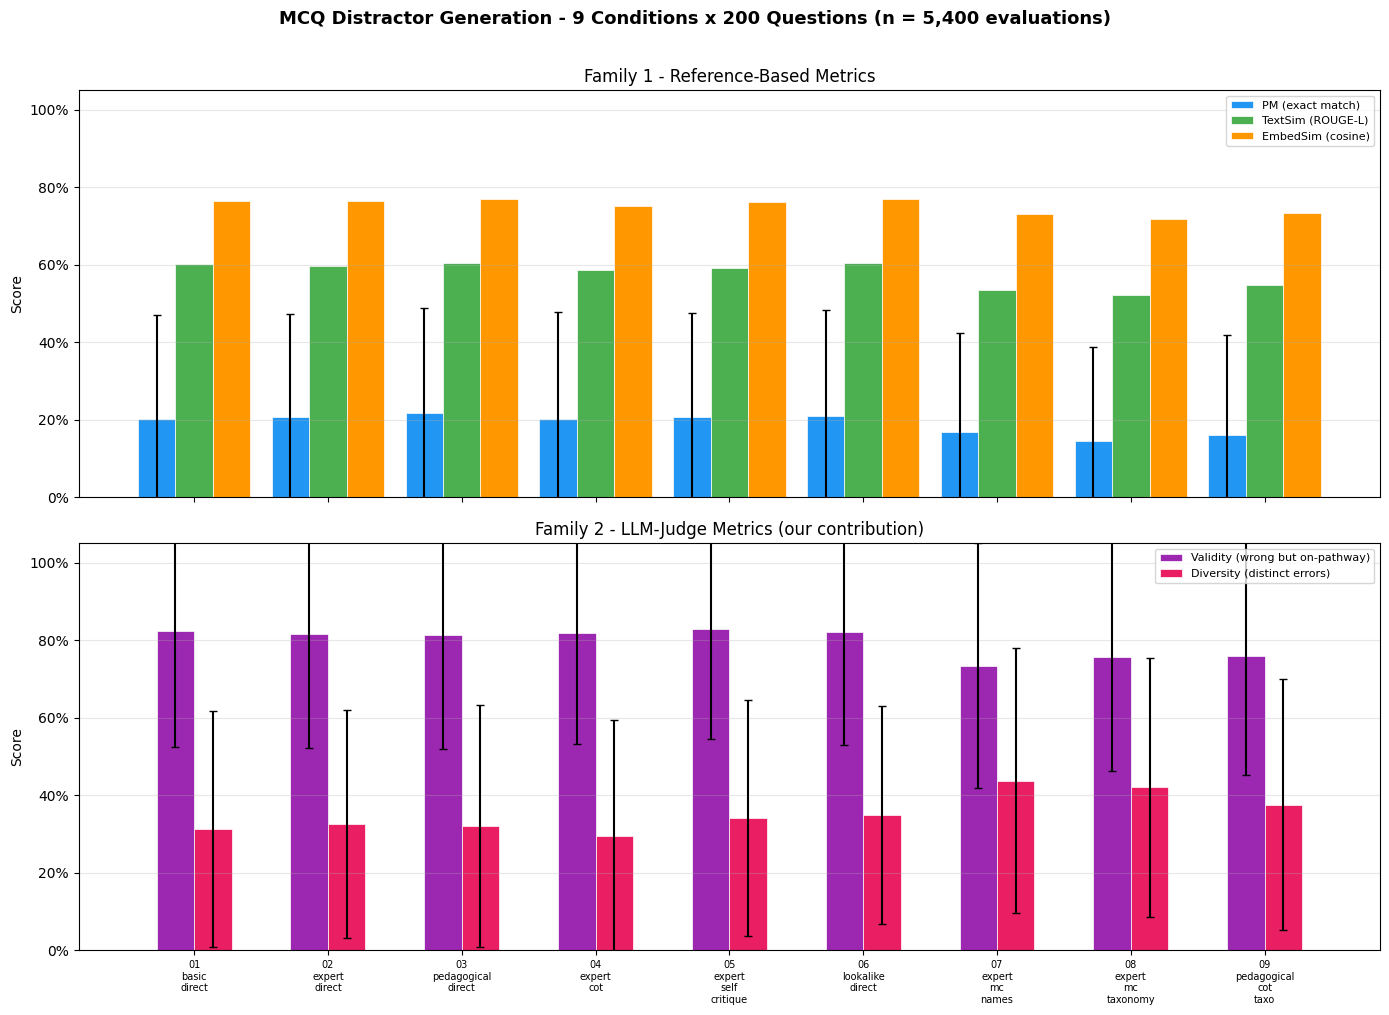

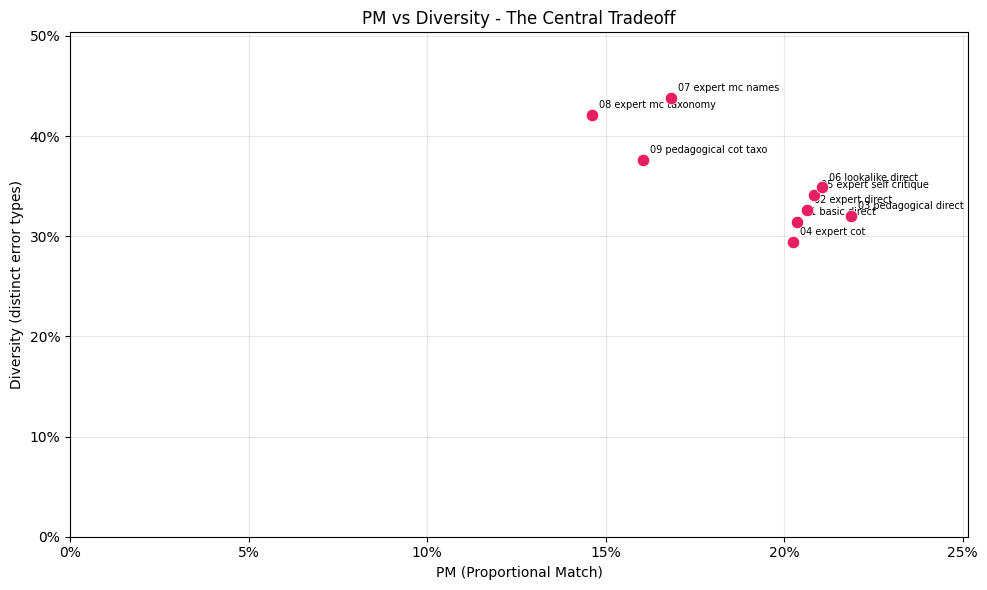

─────────────────────────────────────────────────────────────────────────────────────────────────────────────────
Condition                                     PM  TextSim EmbedSim        Validity   Diversity
─────────────────────────────────────────────────────────────────────────────────────────────────────────────────
01  Basic + Direct                20.4% +- 26.8%    0.602    0.764  82.4% +- 30.1% 31.4% +- 30.5%
02  Expert + Direct  * baseline   20.6% +- 26.6%    0.596    0.764  81.5% +- 29.3% 32.6% +- 29.5%
03  Pedagogical + Direct          21.9% +- 27.0%    0.606    0.770  81.5% +- 29.6% 32.0% +- 31.1%
04  Expert + CoT                  20.2% +- 27.7%    0.587    0.751  81.8% +- 28.6% 29.4% +- 29.9%
05  Expert + Self-Critique        20.8% +- 26.7%    0.593    0.761  83.0% +- 28.3% 34.2% +- 30.5%
06  Lookalike + Direct            21.1% +- 27.2%    0.604    0.769  82.2% +- 29.1% 34.9% +- 28.1%
07  Expert + MC Names             16.8% +- 25.6%    0.535    0.730  73.5% +- 31.6% 43.8% 

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import json
from pathlib import Path

# Load data (real results if available, else inline)
agg_path = Path('../experiments/results/phase1_mcq/aggregated.json')
if agg_path.exists():
    print(f'Loading real results from {agg_path}\n')
    with open(agg_path) as f:
        agg_data = json.load(f)
    class RP:
        def __init__(self, d):
            self.condition_name = d['condition']; self.n = d['n_questions']
            self.pm = d['PM']; self.pm_s = d['PM_std']
            self.ts = d['TextSim']; self.es = d['EmbedSim']
            self.val = d['Validity']; self.val_s = d['Validity_std']
            self.div = d['Diversity']; self.div_s = d['Diversity_std']
        @property
        def avg_pm(self): return self.pm
        @property
        def std_pm(self): return self.pm_s
        @property
        def avg_text_similarity(self): return self.ts
        @property
        def avg_embed_similarity(self): return self.es
        @property
        def avg_validity(self): return self.val
        @property
        def std_validity(self): return self.val_s
        @property
        def avg_diversity(self): return self.div
        @property
        def std_diversity(self): return self.div_s
        def summary(self):
            return {'condition': self.condition_name, 'n_questions': self.n,
                    'PM': self.pm, 'PM_std': self.pm_s,
                    'TextSim': self.ts, 'EmbedSim': self.es,
                    'Validity': self.val, 'Validity_std': self.val_s,
                    'Diversity': self.div, 'Diversity_std': self.div_s}
    results = [RP(v) for v in agg_data.values()]
else:
    results = all_results

# Sort by condition name
results.sort(key=lambda cr: cr.condition_name)
labels = [cr.condition_name for cr in results]
pm     = [cr.avg_pm for cr in results]
pm_s   = [cr.std_pm for cr in results]
tsim   = [cr.avg_text_similarity for cr in results]
esim   = [cr.avg_embed_similarity for cr in results]
val    = [cr.avg_validity for cr in results]
val_s  = [cr.std_validity for cr in results]
div    = [cr.avg_diversity for cr in results]
div_s  = [cr.std_diversity for cr in results]

x = np.arange(len(labels))
width = 0.28

# Figure 1: Grouped bar chart
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 10), sharex=True)

ax1.bar(x - width, pm, width, yerr=pm_s, capsize=3,
        color='#2196F3', label='PM (exact match)', edgecolor='white', linewidth=0.5)
ax1.bar(x, tsim, width, color='#4CAF50', label='TextSim (ROUGE-L)',
        edgecolor='white', linewidth=0.5)
ax1.bar(x + width, esim, width, color='#FF9800', label='EmbedSim (cosine)',
        edgecolor='white', linewidth=0.5)
ax1.set_ylabel('Score')
ax1.set_title('Family 1 - Reference-Based Metrics')
ax1.legend(loc='upper right', fontsize=8)
ax1.set_ylim(0, 1.05)
ax1.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1, decimals=0))
ax1.grid(axis='y', alpha=0.3)

ax2.bar(x - width/2, val, width, yerr=val_s, capsize=3,
        color='#9C27B0', label='Validity (wrong but on-pathway)', edgecolor='white', linewidth=0.5)
ax2.bar(x + width/2, div, width, yerr=div_s, capsize=3,
        color='#E91E63', label='Diversity (distinct errors)', edgecolor='white', linewidth=0.5)
ax2.set_ylabel('Score')
ax2.set_title('Family 2 - LLM-Judge Metrics')
ax2.set_xticks(x)
ax2.set_xticklabels([l.replace('_', '\n') for l in labels], fontsize=7)
ax2.legend(loc='upper right', fontsize=8)
ax2.set_ylim(0, 1.05)
ax2.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1, decimals=0))
ax2.grid(axis='y', alpha=0.3)

fig.suptitle('MCQ Distractor Generation - %d Conditions x 200 Questions (n = 5,400 evaluations)' % len(labels),
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

# Figure 2: PM vs Diversity tradeoff
fig, ax = plt.subplots(figsize=(10, 6))
for i, label in enumerate(labels):
    short = label.replace('_', ' ')
    ax.annotate(short, (pm[i], div[i]), fontsize=7,
                textcoords='offset points', xytext=(5, 5))
ax.scatter(pm, div, s=80, c='#E91E63', edgecolors='white', linewidth=0.5, zorder=3)
ax.set_xlabel('PM (Proportional Match)')
ax.set_ylabel('Diversity (distinct error types)')
ax.set_title('PM vs Diversity - The Central Tradeoff')
ax.set_xlim(0, max(pm) * 1.15)
ax.set_ylim(0, max(div) * 1.15)
ax.xaxis.set_major_formatter(mticker.PercentFormatter(xmax=1, decimals=0))
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1, decimals=0))
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Final Results Table
NAME_MAP = {
    '01_basic_direct':         '01  Basic + Direct',
    '02_expert_direct':        '02  Expert + Direct  * baseline',
    '03_pedagogical_direct':   '03  Pedagogical + Direct',
    '04_expert_cot':           '04  Expert + CoT',
    '05_expert_self_critique': '05  Expert + Self-Critique',
    '06_lookalike_direct':     '06  Lookalike + Direct',
    '07_expert_mc_names':      '07  Expert + MC Names',
    '08_expert_mc_taxonomy':   '08  Expert + MC Taxonomy',
    '09_pedagogical_cot_taxo': '09  Pedagogical + CoT + Taxonomy',
}

SEP = chr(0x2500) * 113
print(SEP)
print('%-33s %14s %8s %8s %15s %11s' % (
    'Condition', 'PM', 'TextSim', 'EmbedSim', 'Validity', 'Diversity'))
print(SEP)
for cr in results:
    s = cr.summary()
    label = NAME_MAP.get(cr.condition_name, cr.condition_name)
    pm_str  = '%.1f%% +- %.1f%%' % (s['PM'] * 100, s['PM_std'] * 100)
    val_str = '%.1f%% +- %.1f%%' % (s['Validity'] * 100, s['Validity_std'] * 100)
    div_str = '%.1f%% +- %.1f%%' % (s['Diversity'] * 100, s['Diversity_std'] * 100)
    print('%-33s %14s %8.3f %8.3f %15s %11s' % (
        label, pm_str, s['TextSim'], s['EmbedSim'], val_str, div_str))
print(SEP)
print()
print('Feng et al. 2024 baselines (PM only, not normalized):  kNN 38.5%  |  CoT 30.4%  |  RB 27.2%  |  Zero-shot ~23.6%')
print('Our best PM (21.9%) = Feng zero-shot - comparable despite stricter normalized matching.')
print('F2 metrics (Validity, Diversity) are our contribution; no external baselines exist.')
print()
print('n = %d conditions x 3 runs x 200 questions = %d question-evaluations' % (len(results), len(results) * 3 * 200))

## 10. Takeaways for PF Exercise Generation

What Phase 1a teaches us about generating full Productive Failure exercises.

### 1. Self-Critique is the best strategy. Use it.

Condition #05 (Expert + Self-Critique) gave the **best Validity (83.0%)**, 3rd-best Diversity (34.2%), and competitive PM (20.8%).

**For PF generation:** prompt the model to generate a draft exercise, then critique it against Kapur's 5 criteria, then revise. Do not settle for first-pass output.

---

### 2. Chain-of-Thought hurts creativity. Avoid it.

Condition #04 (Expert + CoT) produced the **worst Diversity (29.4%)** — reasoning chains make the model converge on textbook-style answers that all stem from the same error type.

**For PF generation:** do NOT ask the model to "think step-by-step" before writing the exercise. Let it be ill-structured first, then check quality after.

---

### 3. Student simulation works. Think like a learner.

Condition #06 (Lookalike) **outperformed baseline on every F2 metric** (Validity 82.2%, Diversity 34.9%) — the "think like a student who makes mistakes" persona produces more authentic, varied distractors.

**For PF generation:** prompt the model to imagine being a confused learner, not an expert teacher. The exercise should feel authentically challenging from the student's perspective.

---

### 4. Constraints create diversity but hurt quality. Use them lightly.

MC-conditioned variants (#07, #08) boosted Diversity by ~33% (32% → 44%) but dropped PM by ~30% (21% → 15%) and Validity by ~10% (82% → 74%). **Hard constraints force diversity at the cost of plausibility.**

**For PF generation:** give Kapur's ill-structuredness criteria as *guidelines*, not hard constraints. Let the model exercise creative freedom within the PF framework.

---

### 5. Do not stack techniques. Pick one and iterate.

Condition #09 (Pedagogical + CoT + Taxonomy — "kitchen sink") **underperformed individual axes on every single metric.** More is not better.

**For PF generation:** use Self-Critique alone first. Add one enhancement at a time and measure whether it actually helps.

---

### 6. The PF rubric works. Focus on APK, AE, and OE.

Our F3 test (30 questions) showed **APK (2.43/3), AE (2.43/3), and OE (1.73/3)** are the most discriminating PF rubric dimensions for distractor evaluation. **SSC was flat at 2.0** (judge always says "moderate") and **MR was low at 1.27** (distractors are all numeric — MR only makes sense for narrative problems).

**For PF evaluation:** prioritize Affective Engagement (does this feel real to a student?), Open-Endedness (are there multiple solution pathways?), and Prior Knowledge activation (does the exercise connect to known concepts?).